# 00 · Como o Radar Remoto funciona

O Radar Remoto ajuda quem está no Brasil a encontrar vagas internacionais e conferir por que cada vaga foi recomendada, descartada ou ficou pendente.

Leia este notebook antes de executar os demais. As imagens já estão no arquivo. Você não precisa de chave, internet ou kernel para acompanhar a explicação.

## Onde cada peça fica

| Pasta | O que você encontra |
|---|---|
| `src/` | O pacote Python com o código do agente. O chat e os notebooks chamam funções desse pacote. |
| `notebooks/` | Os exemplos da disciplina: indexação, chain, ferramentas, memória e avaliação. |
| `data/` | Currículo e vagas de exemplo, casos de avaliação e arquivos locais gerados pelo projeto. |
| `scripts/` | Comandos para preparar os dados, abrir a CLI e rodar a avaliação. |

Por exemplo, o notebook de indexação usa `from src.rag import build_index`. O notebook mostra a execução; a função que lê o PDF e cria o índice fica em `src/rag.py`.

| Arquivo em `src/` | Papel |
|---|---|
| `api.py` e `agente.py` | A API recebe a mensagem em `POST /chat`. O agente coordena a resposta. |
| `config.py`, `prompts.py` e `executor.py` | Carregam a configuração do modelo, montam as instruções e executam chamadas de ferramentas. |
| `tools.py` e `repository.py` | Consultam os provedores de vagas e câmbio e mantêm os registros no SQLite. |
| `rag.py` e `memoria.py` | Separam a busca nos documentos da memória da conversa. |
| `rules.py` e `verificador.py` | Aplicam filtros e conferem afirmações com base nos trechos dos anúncios. |

## Antes do chat: do currículo ao índice

O Docling lê o PDF do currículo. O código divide o texto do currículo e das vagas de exemplo em trechos e mantém a fonte de cada um. Um modelo local converte os trechos em vetores, chamados *embeddings*. O FAISS guarda esses vetores em um índice e encontra trechos com significado próximo ao da pergunta.

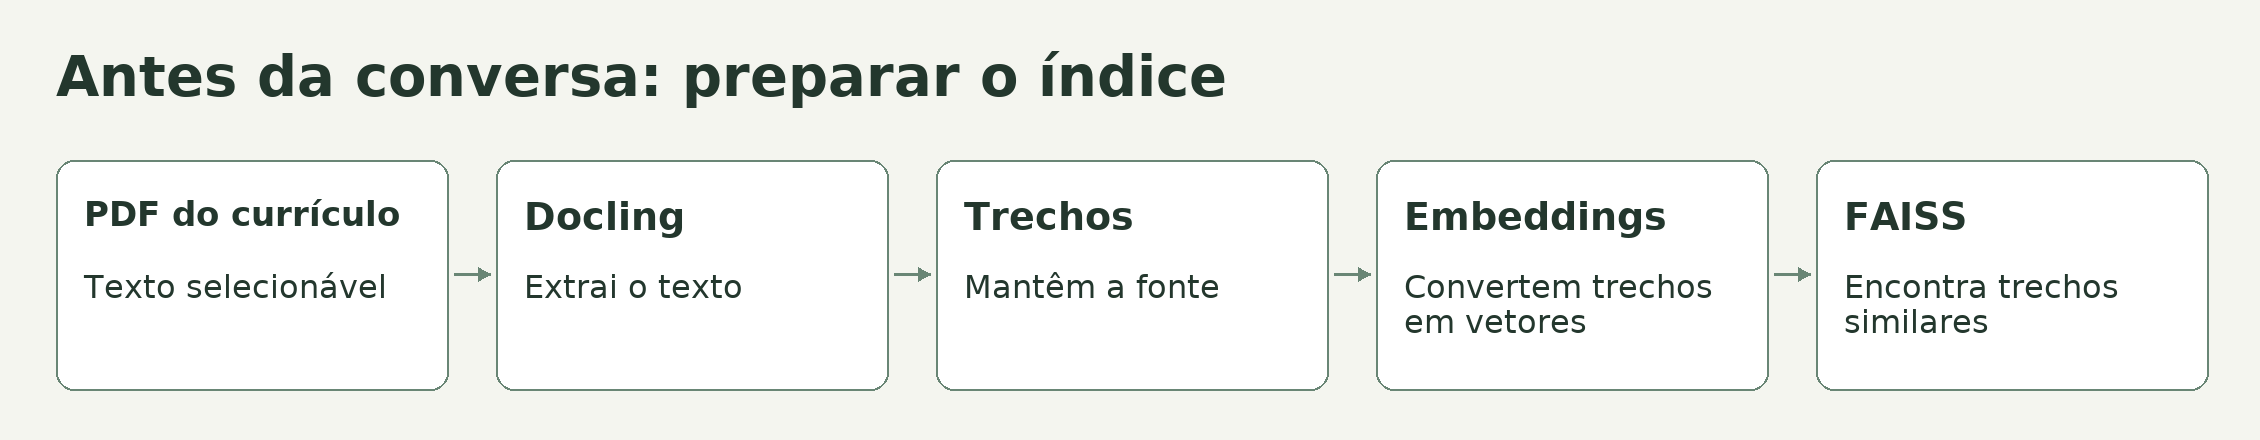

**E o OCR?** OCR reconhece letras em imagens, como um currículo digitalizado. O PDF de exemplo já tem texto selecionável. Por isso, `read_pdf()` usa `do_ocr=False` no código atual. Para aceitar um PDF digitalizado, seria preciso habilitar o OCR e conferir se a extração preserva as informações do currículo.

**O que acontece no chat?** A preparação grava o índice em disco. Durante a conversa, o agente carrega esse índice quando precisa encontrar um trecho do currículo. Ele não reprocessa o PDF a cada pergunta.

## Durante o chat: como o agente entende “a segunda”

Depois de mostrar uma lista de vagas, o agente guarda a ordem dos IDs naquela sessão. Se você pedir **“Converta o salário da segunda”**, ele recupera o segundo ID dessa lista. Assim, uma nova busca não troca a vaga à qual você se referiu.

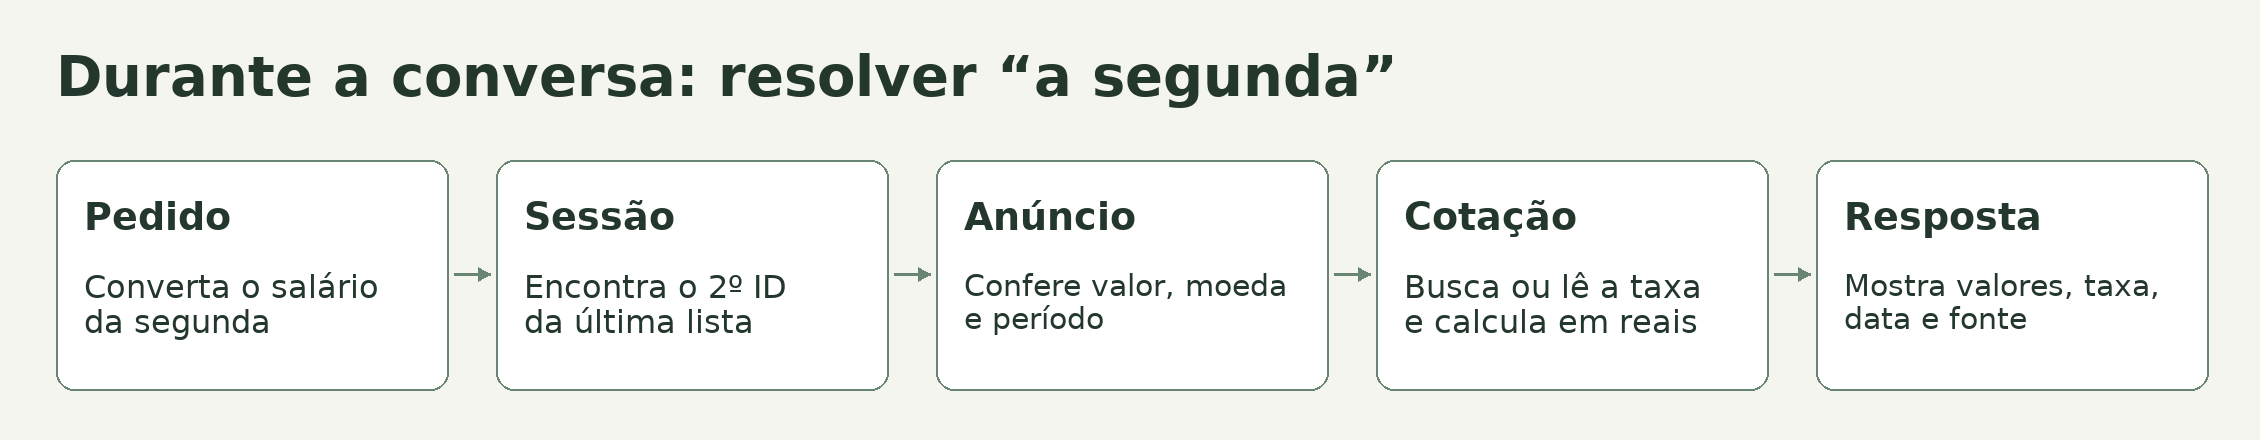

Na demonstração, a segunda vaga é a da Orbit Works. O anúncio informa **€ 5.400 por mês**. Com a cotação fictícia de **R$ 6,00 por euro**, o agente calcula **R$ 32.400 por mês** e mostra a data e a origem da taxa. Se faltar moeda ou período, ele informa que não dá para verificar a conversão. Sem uma lista naquela sessão, ele pede que você busque vagas primeiro.

Em uma busca, a verificação também pode mudar a decisão. Se a proposta diz que a vaga aceita candidatos no Brasil e o anúncio diz `Remote, US only.`, o agente descarta a vaga e mostra o trecho que explica o descarte.

## O que roda no computador e o que usa a internet

| Onde | O que acontece |
|---|---|
| **Localmente** | Docling lê o PDF, os embeddings e o FAISS permitem recuperar trechos, o SQLite guarda registros e o NLI compara uma afirmação com sua fonte. O primeiro preparo pode baixar pesos públicos. |
| **Modo demo** | O agente usa vagas e cotações fictícias e um modelo com respostas roteirizadas. A demonstração não precisa de chave da OpenAI. |
| **Modo real** | `src/config.py` importa `ChatOpenAI` da biblioteca `langchain_openai` e aponta para o modelo indicado por `OPENAI_MODEL`. O modelo é chamado pela API da OpenAI; seus pesos não rodam no computador. As ferramentas também consultam Remotive, Arbeitnow e AwesomeAPI. |
| **Avaliação remota** | O LangSmith registra o experimento quando você executa a avaliação remota. O script atual usa a OpenAI para julgar as respostas da demonstração. |

## O que ler depois

1. [01 · Indexação](01_indexacao.ipynb): veja o PDF virar um índice FAISS.
2. [02 · Chain](02_chain_mvp.ipynb): veja o texto virar um perfil estruturado.
3. [03 · ReAct](03_agente_react.ipynb): veja como o agente aciona ferramentas.
4. [04 · Memória](04_memoria.ipynb): acompanhe uma conversa em vários turnos.
5. [05 · Ferramentas e RAG](05_ferramentas_rag.ipynb): confira a consulta SQL e a recuperação de trechos.
6. [06 · Integração e avaliação](06_integrador_avaliacao.ipynb): teste o fluxo completo e veja os resultados.

O [README](../README.md) mostra como rodar o projeto. A [matriz de evidências](../docs/progresso.md) aponta onde conferir cada item da rubrica.